In [2]:
# CELL 1: Setup and Data Preparation
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for the notebook
sns.set_theme(style="darkgrid")

# 1. Load the dataset
df = pd.read_csv('Atlantic_France.csv')

# 2. Data Validation & Preparation
df['date'] = pd.to_datetime(df['date'], format='%d-%m-%Y', errors='coerce')
df['duration_minutes'] = df['duration_ms'] / 60000
df['is_explicit'] = df['is_explicit'].astype(bool)

# Create duration buckets
def categorize_dur(m):
    if m < 2.5: return "Short (< 2.5m)"
    elif m <= 3.5: return "Medium (2.5 - 3.5m)"
    else: return "Long (> 3.5m)"
df['duration_bucket'] = df['duration_minutes'].apply(categorize_dur)

# Create rank tiers
df['rank_tier'] = pd.cut(df['position'], bins=[0, 10, 25, 50], labels=['Top 10', 'Top 25', 'Top 50'])

print("Data successfully loaded and cleaned!")
print(f"Total rows: {len(df)}")
df.head()

Data successfully loaded and cleaned!
Total rows: 27800


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,duration_minutes,duration_bucket,rank_tier
0,2024-05-18,1,LA RUE,No Limit & Gazo & Damso,72,225137,single,1,True,https://i.scdn.co/image/ab67616d0000b27384f245...,3.752283,Long (> 3.5m),Top 10
1,2024-05-18,2,C'est carré le S,Naps,74,201533,album,22,False,https://i.scdn.co/image/ab67616d0000b27348f7c1...,3.358883,Medium (2.5 - 3.5m),Top 10
2,2024-05-18,3,Freestyle LVL UP 1,Ninho,76,114182,single,1,True,https://i.scdn.co/image/ab67616d0000b273fbe613...,1.903033,Short (< 2.5m),Top 10
3,2024-05-18,4,Bolide allemand,SDM,79,176746,album,15,True,https://i.scdn.co/image/ab67616d0000b273455e89...,2.945767,Medium (2.5 - 3.5m),Top 10
4,2024-05-18,5,Freestyle LVL UP 2,Ninho,71,149064,single,1,True,https://i.scdn.co/image/ab67616d0000b27351f1cb...,2.484400,Short (< 2.5m),Top 10


--- EXPLICIT CONTENT SENSITIVITY ---
Explicit Share: 56.3%
Clean Share: 43.7%

Average Popularity:
Explicit Tracks: 73.3
Clean Tracks: 80.9


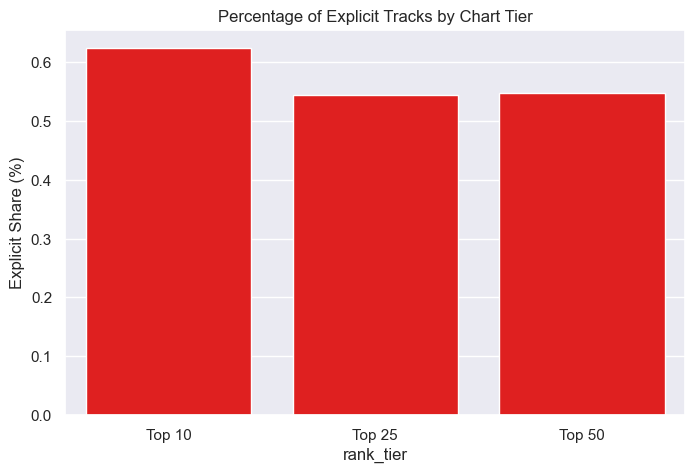

In [2]:
# CELL 2: Explicit Content Analysis
print("--- EXPLICIT CONTENT SENSITIVITY ---")

# 1. Share of Explicit vs Clean
explicit_counts = df['is_explicit'].value_counts(normalize=True) * 100
print(f"Explicit Share: {explicit_counts.get(True, 0):.1f}%")
print(f"Clean Share: {explicit_counts.get(False, 0):.1f}%")

# 2. Popularity Comparison
pop_comparison = df.groupby('is_explicit')['popularity'].mean()
print("\nAverage Popularity:")
print(f"Explicit Tracks: {pop_comparison.get(True, 0):.1f}")
print(f"Clean Tracks: {pop_comparison.get(False, 0):.1f}")

# 3. Visual: Explicit Share across Rank Tiers
plt.figure(figsize=(8, 5))
sns.barplot(data=df, x='rank_tier', y='is_explicit', errorbar=None, color='red')
plt.title("Percentage of Explicit Tracks by Chart Tier")
plt.ylabel("Explicit Share (%)")
plt.show()

--- FORMAT & ALBUM STRUCTURE ---
Release Format Breakdown:
album_type
album          52.9%
single         47.1%
compilation     0.0%
Name: proportion, dtype: object

Correlation between Album Size and Track Popularity: -0.343
Insight: Larger albums tend to slightly DILUTE track popularity.


C:\Users\garvi\AppData\Local\Temp\ipykernel_3120\3222361313.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='album_type', y='position', palette='Set2')


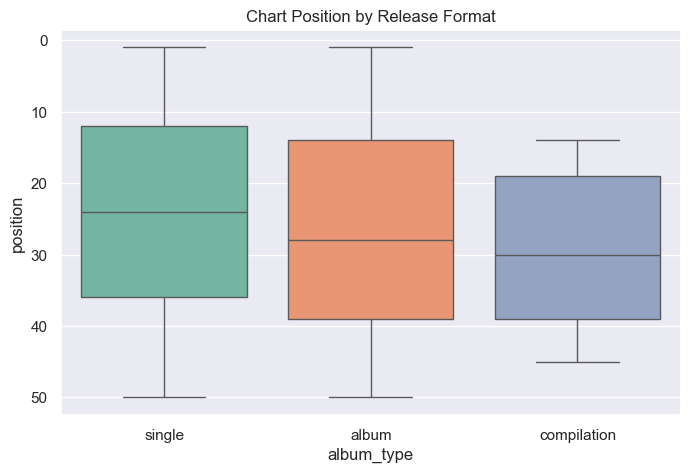

In [3]:
# CELL 3: Format & Structure Analysis
print("--- FORMAT & ALBUM STRUCTURE ---")

# 1. Single vs Album Distribution
format_counts = df['album_type'].value_counts(normalize=True) * 100
print("Release Format Breakdown:")
print(format_counts.round(1).astype(str) + '%')

# 2. Album Dilution Analysis (Does a 20-track album hurt popularity?)
correlation = df['total_tracks'].corr(df['popularity'])
print(f"\nCorrelation between Album Size and Track Popularity: {correlation:.3f}")
if correlation < 0:
    print("Insight: Larger albums tend to slightly DILUTE track popularity.")
else:
    print("Insight: Larger albums do NOT dilute popularity in this dataset.")

# 3. Visual: Format vs Position
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='album_type', y='position', palette='Set2')
plt.gca().invert_yaxis() # Rank 1 at the top
plt.title("Chart Position by Release Format")
plt.show()

--- SONG DURATION PREFERENCES ---
Average Song Duration: 3.09 minutes

Duration Bucket Breakdown:
duration_bucket
Medium (2.5 - 3.5m)    63.6%
Long (> 3.5m)          23.5%
Short (< 2.5m)         12.9%
Name: proportion, dtype: object


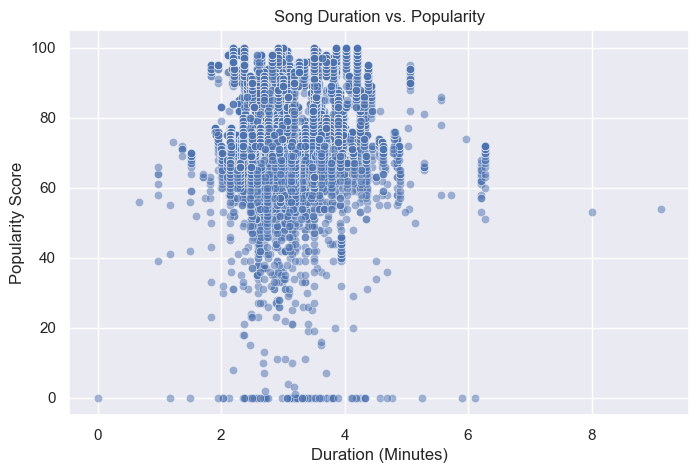

In [4]:
# CELL 4: Duration Analysis
print("--- SONG DURATION PREFERENCES ---")

# 1. Average Duration
avg_dur = df['duration_minutes'].mean()
print(f"Average Song Duration: {avg_dur:.2f} minutes")

# 2. Duration Buckets Breakdown
bucket_counts = df['duration_bucket'].value_counts(normalize=True) * 100
print("\nDuration Bucket Breakdown:")
print(bucket_counts.round(1).astype(str) + '%')

# 3. Visual: Duration vs Popularity
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='duration_minutes', y='popularity', alpha=0.5)
plt.title("Song Duration vs. Popularity")
plt.xlabel("Duration (Minutes)")
plt.ylabel("Popularity Score")
plt.show()

In [5]:
# CELL 5: Official Project KPIs
print("=== ATLANTIC RECORDS OFFICIAL KPIs ===")

kpi_explicit_share = (df['is_explicit'].sum() / len(df)) * 100
kpi_clean_ratio = 100 - kpi_explicit_share
kpi_single_ratio = (len(df[df['album_type'] == 'single']) / len(df)) * 100
kpi_album_ratio = 100 - kpi_single_ratio
kpi_avg_duration = df['duration_minutes'].mean()
kpi_album_impact = df['total_tracks'].corr(df['popularity'])

print(f"1. Explicit Content Share: {kpi_explicit_share:.1f}%")
print(f"2. Clean Content Dominance Ratio: {kpi_clean_ratio:.1f}%")
print(f"3. Single vs Album Track Ratio: {kpi_single_ratio:.1f}% Singles / {kpi_album_ratio:.1f}% Albums")
print(f"4. Average Song Duration: {kpi_avg_duration:.2f} mins")
print(f"5. Album Size Impact Index (Correlation): {kpi_album_impact:.3f}")

=== ATLANTIC RECORDS OFFICIAL KPIs ===
1. Explicit Content Share: 56.3%
2. Clean Content Dominance Ratio: 43.7%
3. Single vs Album Track Ratio: 47.1% Singles / 52.9% Albums
4. Average Song Duration: 3.09 mins
5. Album Size Impact Index (Correlation): -0.343


In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv('Atlantic_France.csv')

# 1. Convert duration to minutes
df['duration_minutes'] = df['duration_ms'] / 60000

# 2. Standardize album type (ensure lowercase)
df['album_type'] = df['album_type'].str.lower()

# 3. Validate explicit flag consistency
df['is_explicit'] = df['is_explicit'].astype(bool)

# 4. Create Rank Tiers for later analysis
df['rank_tier'] = pd.cut(df['position'], bins=[0, 10, 25, 50], labels=['Top 10', 'Top 25', 'Top 50'])

# 5. Check if we have 50 entries per day (Data Validation)
entries_per_day = df.groupby('date').size()
print("Average entries per day:", entries_per_day.mean())

df.head()

Average entries per day: 50.090090090090094


,date,position,song,artist,popularity,duration_ms,album_type,total_tracks,is_explicit,album_cover_url,duration_minutes,rank_tier
0,18-05-2024,1,LA RUE,No Limit & Gazo & Damso,72,225137,single,1,True,https://i.scdn.co/image/ab67616d0000b27384f245...,3.752283,Top 10
1,18-05-2024,2,C'est carré le S,Naps,74,201533,album,22,False,https://i.scdn.co/image/ab67616d0000b27348f7c1...,3.358883,Top 10
2,18-05-2024,3,Freestyle LVL UP 1,Ninho,76,114182,single,1,True,https://i.scdn.co/image/ab67616d0000b273fbe613...,1.903033,Top 10
3,18-05-2024,4,Bolide allemand,SDM,79,176746,album,15,True,https://i.scdn.co/image/ab67616d0000b273455e89...,2.945767,Top 10
4,18-05-2024,5,Freestyle LVL UP 2,Ninho,71,149064,single,1,True,https://i.scdn.co/image/ab67616d0000b27351f1cb...,2.484400,Top 10


--- EXPLICIT CONTENT SENSITIVITY ---
Explicit Content Share: 56.26%
Clean Content Dominance Ratio: 43.74%

Average Popularity - Explicit: 73.33
Average Popularity - Clean: 80.90

Explicit Content % by Rank Tier:
rank_tier
Top 10    62.410072
Top 25    54.544365
Top 50    54.827338
Name: is_explicit, dtype: float64


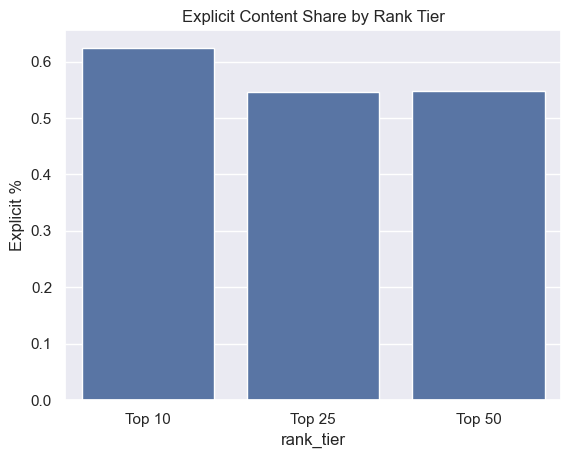

In [7]:
print("--- EXPLICIT CONTENT SENSITIVITY ---")

# 1. Explicit vs non-explicit share
explicit_share = df['is_explicit'].value_counts(normalize=True) * 100
print(f"Explicit Content Share: {explicit_share.get(True, 0):.2f}%")
print(f"Clean Content Dominance Ratio: {explicit_share.get(False, 0):.2f}%")

# 2. Popularity comparison between explicit and clean tracks
pop_comparison = df.groupby('is_explicit')['popularity'].mean()
print(f"\nAverage Popularity - Explicit: {pop_comparison.get(True, 0):.2f}")
print(f"Average Popularity - Clean: {pop_comparison.get(False, 0):.2f}")

# 3. Rank-wise explicit content distribution
tier_explicit = df.groupby('rank_tier', observed=False)['is_explicit'].mean() * 100
print("\nExplicit Content % by Rank Tier:")
print(tier_explicit)

# Visualization
sns.barplot(data=df, x='rank_tier', y='is_explicit', errorbar=None)
plt.title('Explicit Content Share by Rank Tier')
plt.ylabel('Explicit %')
plt.show()

--- RELEASE FORMAT PREFERENCE ---
Album Tracks: 52.86%
Single Tracks: 47.11%

Average Popularity by Format:
album_type
album          72.987138
compilation    79.333333
single         80.747862
Name: popularity, dtype: float64


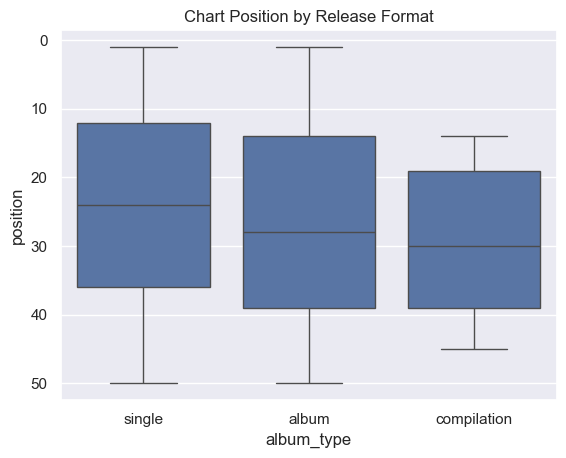

In [8]:
print("--- RELEASE FORMAT PREFERENCE ---")

# 1. Single vs album track representation
format_share = df['album_type'].value_counts(normalize=True) * 100
print(f"Album Tracks: {format_share.get('album', 0):.2f}%")
print(f"Single Tracks: {format_share.get('single', 0):.2f}%")

# 2. Popularity differences by album type
format_pop = df.groupby('album_type')['popularity'].mean()
print("\nAverage Popularity by Format:")
print(format_pop)

# 3. Rank-based format comparison
sns.boxplot(data=df, x='album_type', y='position')
plt.gca().invert_yaxis() # Invert so Rank 1 is at the top
plt.title('Chart Position by Release Format')
plt.show()

--- ALBUM STRUCTURE IMPACT ---
Average tracks per album/release: 9.0
Album Size Impact Index (Correlation): -0.343
Insight: Negative correlation means larger albums tend to DILUTE individual track popularity.


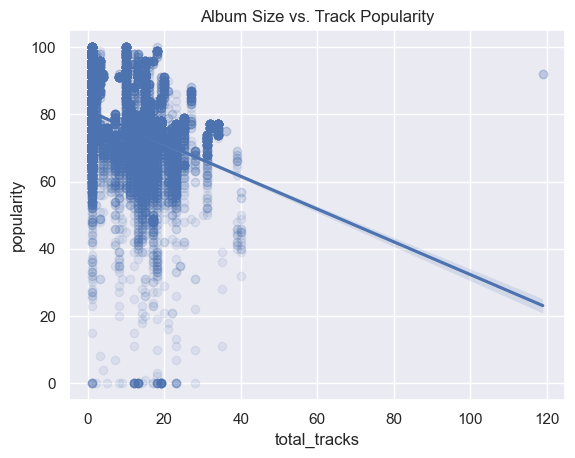

In [9]:
print("--- ALBUM STRUCTURE IMPACT ---")

# 1. Album size (total_tracks) distribution
print(f"Average tracks per album/release: {df['total_tracks'].mean():.1f}")

# 2. Album dilution vs concentration effects (Correlation)
# We calculate the correlation between the number of tracks and the song's popularity
album_impact_index = df['total_tracks'].corr(df['popularity'])
print(f"Album Size Impact Index (Correlation): {album_impact_index:.3f}")

if album_impact_index < 0:
    print("Insight: Negative correlation means larger albums tend to DILUTE individual track popularity.")
else:
    print("Insight: Positive correlation means larger albums STRENGTHEN track popularity.")

# Visualization
sns.regplot(data=df, x='total_tracks', y='popularity', scatter_kws={'alpha':0.1})
plt.title('Album Size vs. Track Popularity')
plt.show()

--- SONG DURATION PREFERENCE ---
Average Song Duration: 3.09 minutes

Duration Bucket Preferences:
duration_bucket
Medium (2.5 - 3.5m)    63.604317
Long (> 3.5m)          23.510791
Short (< 2.5m)         12.884892
Name: proportion, dtype: float64

Average Duration by Rank Tier:
rank_tier
Top 10    3.088150
Top 25    3.081908
Top 50    3.098090
Name: duration_minutes, dtype: float64


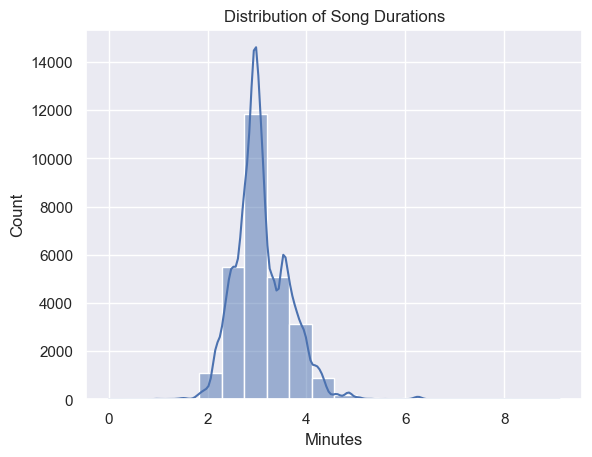

In [10]:
print("--- SONG DURATION PREFERENCE ---")

# 1. Duration distribution across playlist
avg_dur = df['duration_minutes'].mean()
print(f"Average Song Duration: {avg_dur:.2f} minutes")

# 2. Duration buckets (short, medium, long)
def bucket_duration(m):
    if m < 2.5: return "Short (< 2.5m)"
    elif m <= 3.5: return "Medium (2.5 - 3.5m)"
    else: return "Long (> 3.5m)"

df['duration_bucket'] = df['duration_minutes'].apply(bucket_duration)
bucket_share = df['duration_bucket'].value_counts(normalize=True) * 100
print("\nDuration Bucket Preferences:")
print(bucket_share)

# 3. Duration vs rank alignment
tier_duration = df.groupby('rank_tier', observed=False)['duration_minutes'].mean()
print("\nAverage Duration by Rank Tier:")
print(tier_duration)

# Visualization
sns.histplot(df['duration_minutes'], bins=20, kde=True)
plt.title('Distribution of Song Durations')
plt.xlabel('Minutes')
plt.show()

In [11]:
print("=== FINAL PROJECT KPIs FOR EXECUTIVE SUMMARY ===")

kpi_explicit_share = (df['is_explicit'].sum() / len(df)) * 100
kpi_clean_ratio = 100 - kpi_explicit_share
kpi_single_ratio = (len(df[df['album_type'] == 'single']) / len(df)) * 100
kpi_album_ratio = 100 - kpi_single_ratio
kpi_avg_duration = df['duration_minutes'].mean()
kpi_album_impact = df['total_tracks'].corr(df['popularity'])

print(f"1. Explicit Content Share: {kpi_explicit_share:.1f}%")
print(f"2. Clean Content Dominance Ratio: {kpi_clean_ratio:.1f}%")
print(f"3. Single vs Album Track Ratio: {kpi_single_ratio:.1f}% Singles / {kpi_album_ratio:.1f}% Albums")
print(f"4. Average Song Duration: {kpi_avg_duration:.2f} mins")
print(f"5. Album Size Impact Index: {kpi_album_impact:.3f}")

# Content Acceptance Score (Custom Metric: Avg popularity of Top 10 explicit vs clean tracks)
top10_df = df[df['rank_tier'] == 'Top 10']
content_acceptance = top10_df.groupby('is_explicit')['popularity'].mean()
print(f"6. Content Acceptance Score (Top 10 Pop) - Explicit: {content_acceptance.get(True, 0):.1f} | Clean: {content_acceptance.get(False, 0):.1f}")

=== FINAL PROJECT KPIs FOR EXECUTIVE SUMMARY ===
1. Explicit Content Share: 56.3%
2. Clean Content Dominance Ratio: 43.7%
3. Single vs Album Track Ratio: 47.1% Singles / 52.9% Albums
4. Average Song Duration: 3.09 mins
5. Album Size Impact Index: -0.343
6. Content Acceptance Score (Top 10 Pop) - Explicit: 76.1 | Clean: 81.8


In [3]:
df.describe()

,date,position,popularity,duration_ms,total_tracks,duration_minutes
count,27800,27800.000000,27800.000000,27800.000000,27800.000000,27800.000000
mean,2025-02-20 08:32:48.345323776,25.500000,76.645108,185474.848165,8.999856,3.091247
min,2024-05-18 00:00:00,1.000000,0.000000,0.000000,1.000000,0.000000
25%,2024-10-03 18:00:00,13.000000,71.000000,165586.000000,1.000000,2.759767
50%,2025-02-19 12:00:00,25.500000,75.000000,180000.000000,10.000000,3.000000
75%,2025-07-09 06:00:00,38.000000,83.000000,207733.000000,15.000000,3.462217
max,2025-11-27 00:00:00,50.000000,100.000000,547413.000000,119.000000,9.123550
std,NaN,14.431129,11.570874,32436.845058,8.140060,0.540614
